# LeaseLens: exploratory data analysis of the synthetic rental portfolio

**Team:** Raakin Majeed (2404537) · Ishtiyaq Noorani (2408912) · CIA 3, Advanced Algorithm

This notebook is a **supplementary** analysis. The assessed algorithms (Segment Tree and Randomized Quickselect) and every
figure shown in the LeaseLens application are computed in Java. Python is used here only to:

1. independently re-check the Java results;
2. explore the data statistically; and
3. test whether the analysis **recovers the patterns that were deliberately planted** by the data generator, and does **not**
   report patterns that were not planted.

**Read every finding as a statement about this generated portfolio, not about real property markets.** The data is synthetic
(seed 20261124; see `data/GENERATOR_SPEC.md`). Correlations do not imply causation, and nothing here is a judgement about any tenant.

## 1. Setup

In [1]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA = Path('..') / 'data' / 'sample'
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
ANALYSIS_DATE = pd.Timestamp('2026-10-31')
RNG = np.random.default_rng(20261124)

# Chart palette: the same validated categorical slots as the web app (blue, orange, aqua), plus neutral greys.
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
TYPE_COLOURS = {'RESIDENTIAL': BLUE, 'OFFICE': ORANGE, 'RETAIL': AQUA, 'INDUSTRIAL': '#6250d6'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'font.size': 10})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=150, bbox_inches='tight')

def to_paise(series):
    # Rupees with at most 2 decimals -> exact integer paise (avoids floating-point drift).
    return (series * 100).round().astype('int64')

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
print('pandas', pd.__version__, '| numpy', np.__version__, '| scipy', __import__('scipy').__version__)

pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1


## 2. Load and validate the data
The Java loader enforces 20 validation rules. Here the key integrity checks are repeated independently.

In [2]:
properties = pd.read_csv(DATA / 'properties.csv')
tenants = pd.read_csv(DATA / 'tenants.csv')
leases = pd.read_csv(DATA / 'leases.csv', parse_dates=['start_date', 'end_date'])
obligations = pd.read_csv(DATA / 'rent_obligations.csv', parse_dates=['due_date', 'settled_date'])
transactions = pd.read_csv(DATA / 'rent_transactions.csv', parse_dates=['transaction_date'])
expenses = pd.read_csv(DATA / 'expenses.csv', parse_dates=['expense_date'])

for df, col in [(properties, 'acquisition_value'), (leases, 'monthly_rent'), (obligations, 'due_amount'),
                (obligations, 'amount_paid'), (transactions, 'amount_received'), (expenses, 'amount')]:
    df[col + '_paise'] = to_paise(df[col])

paid_by_tx = transactions.groupby('obligation_id')['amount_received_paise'].sum()
checks = {
    'unique property ids': properties.property_id.is_unique,
    'unique lease ids': leases.lease_id.is_unique,
    'unique obligation ids': obligations.obligation_id.is_unique,
    'unique transaction ids': transactions.transaction_id.is_unique,
    'leases -> known properties': leases.property_id.isin(properties.property_id).all(),
    'leases -> known tenants': leases.tenant_id.isin(tenants.tenant_id).all(),
    'obligations -> known leases': obligations.lease_id.isin(leases.lease_id).all(),
    'transactions -> known obligations': transactions.obligation_id.isin(obligations.obligation_id).all(),
    'expenses -> known properties': expenses.property_id.isin(properties.property_id).all(),
    'lease end >= start': (leases.end_date >= leases.start_date).all(),
    'amounts > 0': bool((leases.monthly_rent_paise > 0).all() and (expenses.amount_paise > 0).all()
                         and (transactions.amount_received_paise > 0).all()),
    'declared amount_paid == sum of transactions': bool(
        (obligations.set_index('obligation_id').amount_paid_paise == paid_by_tx.reindex(obligations.obligation_id).fillna(0)
         .astype('int64').values).all()),
    'no overpayment': bool((paid_by_tx <= obligations.set_index('obligation_id').due_amount_paise.reindex(paid_by_tx.index)).all()),
    'required values present': not any(df.drop(columns=[c for c in ['settled_date'] if c in df]).isna().any().any()
                                       for df in [properties, tenants, leases, obligations, transactions, expenses]),
}
summary = pd.Series(checks, name='passed').to_frame()
display(summary)
assert summary.passed.all(), 'An integrity check failed'
print({name: len(df) for name, df in [('properties', properties), ('tenants', tenants), ('leases', leases),
       ('obligations', obligations), ('transactions', transactions), ('expenses', expenses)]})

,passed
unique property ids,True
unique lease ids,True
unique obligation ids,True
unique transaction ids,True
leases -> known properties,True
leases -> known tenants,True
obligations -> known leases,True
transactions -> known obligations,True
expenses -> known properties,True
lease end >= start,True


{'properties': 50, 'tenants': 196, 'leases': 251, 'obligations': 3974, 'transactions': 4238, 'expenses': 9688}


## 3. Derived tables
Days late (completed payments), open balances at the analysis date, and property attributes on every row.

In [3]:
lease_prop = leases.set_index('lease_id')['property_id']
ob = obligations.copy()
ob['property_id'] = ob.lease_id.map(lease_prop)
ob = ob.merge(properties[['property_id', 'property_type', 'rentable_area_sqft']], on='property_id')
ob['settled'] = ob.settled_date.notna() & (ob.settled_date <= ANALYSIS_DATE)
ob['days_late'] = np.where(ob.settled, (ob.settled_date - ob.due_date).dt.days.clip(lower=0), np.nan)
ob['balance_paise'] = ob.due_amount_paise - ob.amount_paid_paise
ob['days_overdue'] = np.where(~ob.settled & (ob.due_date <= ANALYSIS_DATE), (ANALYSIS_DATE - ob.due_date).dt.days, np.nan)

tx = transactions.merge(ob[['obligation_id', 'property_id']], on='obligation_id')
ex = expenses.merge(properties[['property_id', 'property_type', 'rentable_area_sqft']], on='property_id')
completed = ob[ob.settled]
open_ob = ob[~ob.settled & (ob.due_date <= ANALYSIS_DATE)]
print(f'{len(completed):,} completed payments, {len(open_ob):,} open obligations at {ANALYSIS_DATE.date()}')

3,918 completed payments, 56 open obligations at 2026-10-31


## 4. Independent check against the Java application
`api_snapshot.json` was captured from the running Java API on this dataset. Each figure is recomputed here with pandas and
compared. The percentiles are recomputed by **full sorting** with the same nearest-rank rule, a different method from the
Java Randomized Quickselect, so agreement is a meaningful cross-check.

In [4]:
snap = json.load(open('api_snapshot.json'))
o = snap['overview']
start, end = pd.Timestamp(o['from']), pd.Timestamp(o['to'])
days = (end - start).days + 1

def pct(n, d):
    return round(100 * n / d + 1e-12, 2) if d else None

billed = ob.loc[ob.due_date.between(start, end), 'due_amount_paise'].sum()
cohort_paid = ob.loc[ob.due_date.between(start, end), 'amount_paid_paise'].sum()
collected = tx.loc[tx.transaction_date.between(start, end), 'amount_received_paise'].sum()
opex = ex.loc[ex.expense_date.between(start, end), 'amount_paise'].sum()
active = leases[(leases.start_date <= ANALYSIS_DATE) & (leases.end_date >= ANALYSIS_DATE)]
area = properties.rentable_area_sqft.sum()
overlap = (leases.end_date.clip(upper=end) - leases.start_date.clip(lower=start)).dt.days + 1
leased_area_days = (leases.leased_area_sqft * overlap.clip(lower=0)).sum()

def nearest_rank(values, p):
    v = np.sort(np.asarray(values))
    return int(v[math.ceil(p / 100 * len(v)) - 1])

rows = [
    ('Rent billed (paise)', o['rentBilledPaise'], billed),
    ('Rent collected (paise)', o['rentCollectedPaise'], collected),
    ('Collection efficiency %', o['collectionEfficiencyPct'], pct(cohort_paid, billed)),
    ('Outstanding receivables (paise)', o['outstandingPaise'], open_ob.balance_paise.sum()),
    ('Operating expenses (paise)', o['operatingExpensesPaise'], opex),
    ('Net operating cash surplus (paise)', o['netOperatingCashSurplusPaise'], collected - opex),
    ('Occupancy on analysis date %', o['occupancyPct'], pct(active.leased_area_sqft.sum(), area)),
    ('Time-weighted occupancy %', o['timeWeightedOccupancyPct'], pct(leased_area_days, area * days)),
    ('Segment-tree full-range net cash flow (paise)', snap['cashflow_full']['netCashFlowPaise'], collected - opex),
    ('Completed payments (n)', snap['percentiles']['population']['completed'], len(completed)),
    ('Open obligations excluded (n)', snap['percentiles']['population']['openExcluded'], len(open_ob)),
]
for p in snap['percentiles']['percentiles']:
    rows.append((f"P{p['p']} days late (Quickselect vs sort)", p['daysLate'], nearest_rank(completed.days_late, float(p['p']))))
retail = completed[completed.property_type == 'RETAIL'].days_late
for p in snap['percentiles_retail']['percentiles']:
    rows.append((f"Retail P{p['p']} days late", p['daysLate'], nearest_rank(retail, float(p['p']))))

check = pd.DataFrame(rows, columns=['measure', 'java_api', 'pandas'])
check['match'] = [abs(float(a) - float(b)) < 1e-9 for a, b in zip(check.java_api, check.pandas)]
display(check)
assert check.match.all(), 'Java and pandas disagree'
print(f'All {len(check)} figures match exactly.')

,measure,java_api,pandas,match
0,Rent billed (paise),"81,331,340,000.00","81,331,340,000.00",True
1,Rent collected (paise),"80,650,640,000.00","80,650,640,000.00",True
2,Collection efficiency %,99.16,99.16,True
3,Outstanding receivables (paise),"680,700,000.00","680,700,000.00",True
4,Operating expenses (paise),"17,692,441,800.00","17,692,441,800.00",True
5,Net operating cash surplus (paise),"62,958,198,200.00","62,958,198,200.00",True
6,Occupancy on analysis date %,94.22,94.22,True
7,Time-weighted occupancy %,94.80,94.80,True
8,Segment-tree full-range net cash flow (paise),"62,958,198,200.00","62,958,198,200.00",True
9,Completed payments (n),"3,918.00","3,918.00",True


All 18 figures match exactly.


## 5. Descriptive statistics

In [5]:
prop = properties.assign(rent_per_sqft_potential=lambda d: np.nan)
by_type = properties.groupby('property_type').agg(properties=('property_id', 'count'),
                                                 rentable_area_sqft=('rentable_area_sqft', 'sum'),
                                                 median_area=('rentable_area_sqft', 'median'))
lease_stats = leases.merge(properties[['property_id', 'property_type']], on='property_id').assign(
    term_months=lambda d: ((d.end_date - d.start_date).dt.days + 1) / 30.44,
    rent_per_sqft=lambda d: d.monthly_rent / d.leased_area_sqft)
display(by_type.join(lease_stats.groupby('property_type').agg(leases=('lease_id', 'count'),
        median_term_months=('term_months', 'median'), median_rent_per_sqft=('rent_per_sqft', 'median'))))
display(ob.status.value_counts().rename('obligations').to_frame())
display(ex.groupby('expense_category').amount.describe()[['count', 'mean', '50%', 'max']].sort_values('count', ascending=False))

,properties,rentable_area_sqft,median_area,leases,median_term_months,median_rent_per_sqft
property_type,,,,,,
INDUSTRIAL,5,228120,"49,560.00",14,48.00,16.38
OFFICE,14,107950,"6,655.00",55,36.01,95.29
RESIDENTIAL,20,60710,"3,070.00",141,22.96,37.75
RETAIL,11,52960,"4,850.00",41,36.01,116.32


,obligations
status,
PAID,3918
PARTIAL,37
UNPAID,19


,count,mean,50%,max
expense_category,,,,
MAINTENANCE,"2,573.00","6,818.79","5,373.00","50,521.00"
MANAGEMENT,"1,800.00","20,035.22","14,562.00","100,189.00"
SECURITY,"1,800.00","11,060.84","8,030.50","41,502.00"
UTILITIES,"1,800.00","10,743.56","7,497.50","71,035.00"
CLEANING,900.00,"9,828.32","8,587.00","24,222.00"
REPAIRS,515.00,"34,886.88","22,158.00","998,064.00"
INSURANCE,150.00,"81,180.00","60,750.00","363,400.00"
PROPERTY_TAX,150.00,"300,527.52","218,429.50","1,502,841.00"


## 6. Rental income distribution

Skewness of monthly rent: 1.33 | of log rent: 0.38


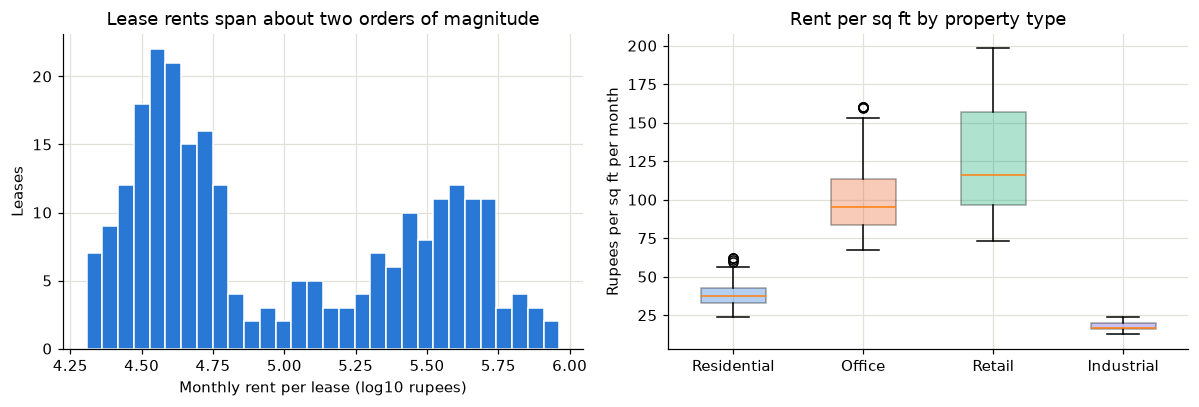

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(np.log10(leases.monthly_rent), bins=30, color=BLUE, edgecolor='white')
axes[0].set_xlabel('Monthly rent per lease (log10 rupees)'); axes[0].set_ylabel('Leases')
axes[0].set_title('Lease rents span about two orders of magnitude')
data = [lease_stats.loc[lease_stats.property_type == t, 'rent_per_sqft'] for t in TYPE_COLOURS]
bp = axes[1].boxplot(data, tick_labels=[t.title() for t in TYPE_COLOURS], patch_artist=True, widths=0.5)
for patch, c in zip(bp['boxes'], TYPE_COLOURS.values()):
    patch.set_facecolor(c); patch.set_alpha(0.35)
axes[1].set_ylabel('Rupees per sq ft per month'); axes[1].set_title('Rent per sq ft by property type')
save(fig, 'fig_rent_distribution')
print('Skewness of monthly rent:', round(stats.skew(leases.monthly_rent), 2),
      '| of log rent:', round(stats.skew(np.log(leases.monthly_rent)), 2))

## 7. Payment-delay distribution
Delays are heavily zero-inflated with a long right tail, which is why the application reports **percentiles** (via Randomized
Quickselect) rather than relying on the mean.

,n,on_time_share_%,mean,P50,P75,P90
property_type,,,,,,
INDUSTRIAL,320.00,75.94,3.94,0.00,0.00,5.00
OFFICE,864.00,60.76,6.70,0.00,5.00,21.00
RESIDENTIAL,"1,889.00",73.80,3.39,0.00,1.00,8.00
RETAIL,845.00,58.46,8.68,0.00,9.00,26.00


Kruskal-Wallis across types: H = 125.7, p = 4.67e-27
Retail > residential (one-sided Mann-Whitney): p = 7.18e-22, rank-biserial effect = 0.19


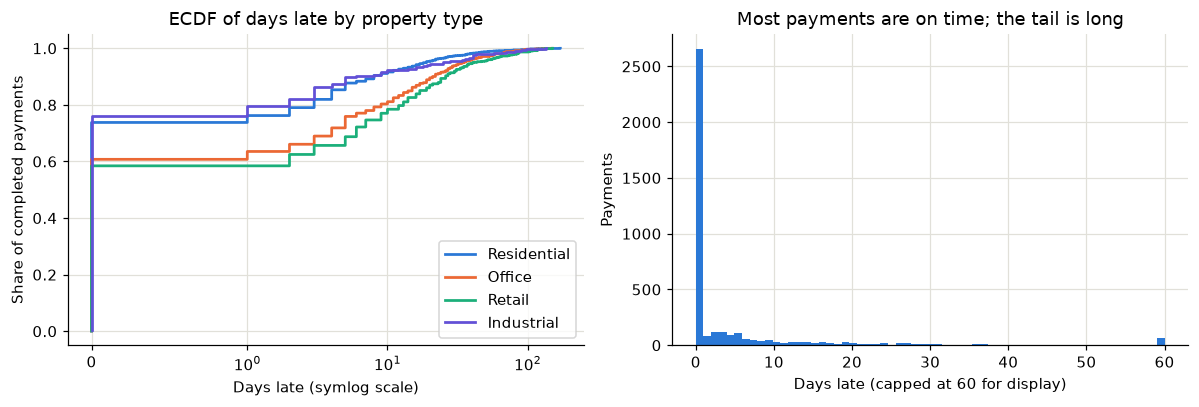

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for t, c in TYPE_COLOURS.items():
    d = np.sort(completed.loc[completed.property_type == t, 'days_late'])
    axes[0].step(d, np.arange(1, len(d) + 1) / len(d), where='post', color=c, label=t.title(), linewidth=1.8)
axes[0].set_xscale('symlog', linthresh=1); axes[0].set_xlabel('Days late (symlog scale)')
axes[0].set_ylabel('Share of completed payments'); axes[0].set_title('ECDF of days late by property type'); axes[0].legend()
axes[1].hist(completed.days_late.clip(upper=60), bins=61, color=BLUE)
axes[1].set_xlabel('Days late (capped at 60 for display)'); axes[1].set_ylabel('Payments')
axes[1].set_title('Most payments are on time; the tail is long')
save(fig, 'fig_delay_distribution')

def summarise(d):
    return pd.Series({'n': len(d), 'on_time_share_%': 100 * (d == 0).mean(), 'mean': d.mean(),
                      'P50': nearest_rank(d, 50), 'P75': nearest_rank(d, 75), 'P90': nearest_rank(d, 90)})
delay_by_type = completed.groupby('property_type').days_late.apply(summarise).unstack()
display(delay_by_type)

groups = [g.days_late.values for _, g in completed.groupby('property_type')]
kw = stats.kruskal(*groups)
mw = stats.mannwhitneyu(completed[completed.property_type == 'RETAIL'].days_late,
                        completed[completed.property_type == 'RESIDENTIAL'].days_late, alternative='greater')
n1 = (completed.property_type == 'RETAIL').sum(); n2 = (completed.property_type == 'RESIDENTIAL').sum()
rank_biserial = 2 * mw.statistic / (n1 * n2) - 1
print(f'Kruskal-Wallis across types: H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}')
print(f'Retail > residential (one-sided Mann-Whitney): p = {mw.pvalue:.2e}, rank-biserial effect = {rank_biserial:.2f}')

## 8. Censoring: what excluding open obligations does
The application's percentiles use completed payments only (as the UI states). Obligations still open at the analysis date are
**right-censored**: we know only that they are *at least* so many days late. A Kaplan–Meier estimate of time-to-full-payment
includes them properly. It is implemented directly below; no survival library is used.

,completed only (application),Kaplan-Meier incl. open
P50,0,0
P75,3,4
P90,16,19
P95,29,37
P99,82,not reached


Share of obligations due by the analysis date that are still open: 1.41%. Because more than 1% never settle within the data, the Kaplan-Meier P99 is not reached.


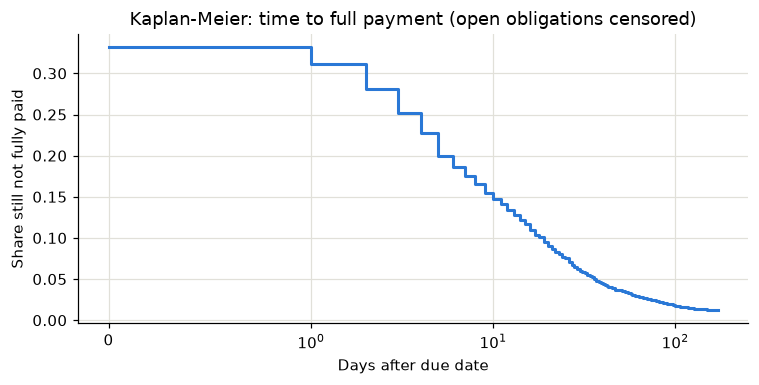

In [8]:
def kaplan_meier(durations, events):
    order = np.argsort(durations)
    d, e = np.asarray(durations)[order], np.asarray(events)[order]
    times = np.unique(d[e == 1])
    surv, s = [], 1.0
    for t in times:
        at_risk = (d >= t).sum()
        deaths = ((d == t) & (e == 1)).sum()
        s *= 1 - deaths / at_risk
        surv.append(s)
    return times, np.array(surv)

due_by = ob[ob.due_date <= ANALYSIS_DATE]
dur = np.where(due_by.settled, due_by.days_late, due_by.days_overdue).astype(float)
evt = due_by.settled.astype(int).values
t_km, s_km = kaplan_meier(dur, evt)

def km_quantile(q):
    # smallest t with P(paid by t) >= q, i.e. S(t) <= 1 - q
    hit = np.where(s_km <= 1 - q)[0]
    return int(t_km[hit[0]]) if len(hit) else 'not reached'

comparison = pd.DataFrame({
    'completed only (application)': [nearest_rank(completed.days_late, p) for p in (50, 75, 90, 95, 99)],
    'Kaplan-Meier incl. open': [km_quantile(p / 100) for p in (50, 75, 90, 95, 99)]},
    index=['P50', 'P75', 'P90', 'P95', 'P99'])
display(comparison)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.step(t_km, s_km, where='post', color=BLUE, linewidth=2)
ax.set_xscale('symlog', linthresh=1); ax.set_xlabel('Days after due date'); ax.set_ylabel('Share still not fully paid')
ax.set_title('Kaplan-Meier: time to full payment (open obligations censored)')
save(fig, 'fig_kaplan_meier')
print(f'Share of obligations due by the analysis date that are still open: {100 * (1 - evt.mean()):.2f}%. '
      'Because more than 1% never settle within the data, the Kaplan-Meier P99 is not reached.')

## 9. Occupancy and vacancy

,longest fully vacant run (months),property_type
property_id,,
P005,8,OFFICE
P006,8,OFFICE


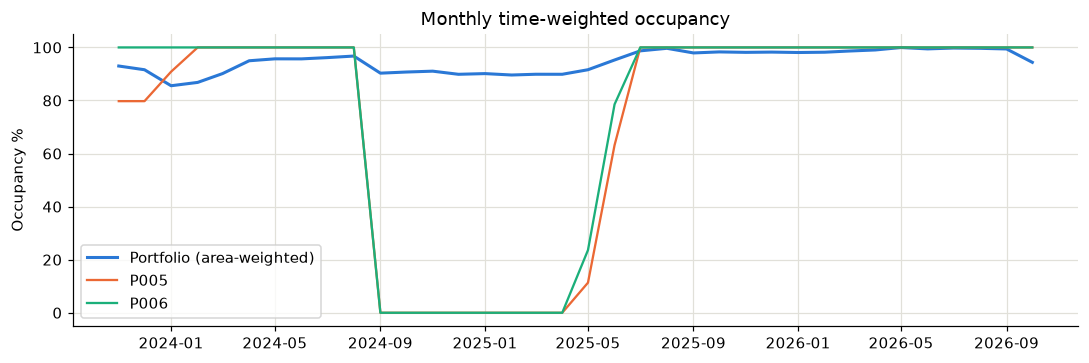

In [9]:
months = pd.period_range('2023-11', '2026-10', freq='M')
occ = pd.DataFrame(index=months, columns=properties.property_id, dtype=float)
for m in months:
    ms, me = m.start_time, m.end_time.normalize()
    ndays = (me - ms).days + 1
    ov = ((leases.end_date.clip(upper=me) - leases.start_date.clip(lower=ms)).dt.days + 1).clip(lower=0)
    leased = (leases.leased_area_sqft * ov).groupby(leases.property_id).sum()
    occ.loc[m] = (leased.reindex(properties.property_id).fillna(0)
                  / (properties.set_index('property_id').rentable_area_sqft * ndays)).values * 100

area_w = properties.set_index('property_id').rentable_area_sqft
portfolio_occ = (occ * area_w).sum(axis=1) / area_w.sum()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(months.to_timestamp(), portfolio_occ, color=BLUE, linewidth=2, label='Portfolio (area-weighted)')
for pid, c in [('P005', ORANGE), ('P006', AQUA)]:
    ax.plot(months.to_timestamp(), occ[pid], color=c, linewidth=1.5, label=pid)
ax.set_ylabel('Occupancy %'); ax.set_ylim(-5, 105); ax.legend(loc='lower left'); ax.set_title('Monthly time-weighted occupancy')
save(fig, 'fig_occupancy')

def longest_zero_run(s):
    best = run = 0
    for v in s:
        run = run + 1 if v == 0 else 0
        best = max(best, run)
    return best

zero_runs = occ.apply(longest_zero_run).sort_values(ascending=False)
vacant = zero_runs[zero_runs >= 8]
display(vacant.rename('longest fully vacant run (months)').to_frame().join(properties.set_index('property_id').property_type))

## 10. Property performance comparisons

In [10]:
cut = pd.Timestamp('2025-05-01')
perf = pd.DataFrame({
    'billed': ob.groupby('property_id').due_amount_paise.sum(),
    'paid': ob.groupby('property_id').amount_paid_paise.sum(),
    'collected': tx.groupby('property_id').amount_received_paise.sum(),
    'opex': ex.groupby('property_id').amount_paise.sum(),
}).join(properties.set_index('property_id')[['property_type', 'rentable_area_sqft', 'acquisition_value_paise']])
perf['collection_eff_%'] = 100 * perf.paid / perf.billed
perf['expense_ratio_%'] = 100 * perf.opex / perf.collected
perf['surplus_per_sqft'] = (perf.collected - perf.opex) / 100 / perf.rentable_area_sqft  # rupees per sq ft over 36 months
perf['avg_occupancy_%'] = occ.mean()
early = ob[ob.due_date < cut].groupby('property_id')[['amount_paid_paise', 'due_amount_paise']].sum()
late = ob[ob.due_date >= cut].groupby('property_id')[['amount_paid_paise', 'due_amount_paise']].sum()
perf['eff_before_May25_%'] = 100 * early.amount_paid_paise / early.due_amount_paise
perf['eff_from_May25_%'] = 100 * late.amount_paid_paise / late.due_amount_paise
perf['eff_change_pts'] = perf['eff_from_May25_%'] - perf['eff_before_May25_%']
cols = ['property_type', 'collection_eff_%', 'eff_before_May25_%', 'eff_from_May25_%', 'eff_change_pts',
        'avg_occupancy_%', 'expense_ratio_%', 'surplus_per_sqft']
print('Largest falls in collection efficiency (May 2025 onwards vs before):')
display(perf.sort_values('eff_change_pts')[cols].head(5))
print('Lowest overall collection efficiency:')
display(perf.sort_values('collection_eff_%')[cols].head(5))

Largest falls in collection efficiency (May 2025 onwards vs before):


,property_type,collection_eff_%,eff_before_May25_%,eff_from_May25_%,eff_change_pts,avg_occupancy_%,expense_ratio_%,surplus_per_sqft
property_id,,,,,,,,
P008,OFFICE,92.68,98.74,86.85,-11.89,100.00,24.11,"3,453.08"
P027,OFFICE,97.91,100.00,96.39,-3.61,79.57,32.85,"1,562.96"
P038,RETAIL,98.35,100.00,96.69,-3.31,100.00,33.52,"2,116.32"
P050,OFFICE,98.48,99.47,97.39,-2.08,90.27,20.76,"2,588.23"
P045,RETAIL,99.23,100.00,98.56,-1.44,96.85,20.75,"2,679.30"


Lowest overall collection efficiency:


,property_type,collection_eff_%,eff_before_May25_%,eff_from_May25_%,eff_change_pts,avg_occupancy_%,expense_ratio_%,surplus_per_sqft
property_id,,,,,,,,
P010,OFFICE,86.50,62.64,100.00,37.36,69.03,40.07,966.51
P008,OFFICE,92.68,98.74,86.85,-11.89,100.00,24.11,"3,453.08"
P036,OFFICE,93.96,86.37,100.00,13.63,85.41,25.79,"1,734.98"
P024,OFFICE,95.94,89.96,100.00,10.04,88.01,25.65,"1,761.67"
P001,RESIDENTIAL,96.06,92.58,99.10,6.52,96.04,21.74,"1,215.69"


## 11. Operating expenses vs collected rent: correlation, not causation
The generator never makes expenses depend on rent collected. Both scale with property size, and two fees (management and
utilities) are set as a percentage of *potential* rent. So we expect:

- a strong raw correlation across properties, driven by size;
- some correlation per square foot as well, driven by rent level, because fees track potential rent;
- **no** relationship between a property's cost intensity and how well it collects (the negative control); and
- no month-to-month co-movement within a property.

,spearman_rho,ci95_low,ci95_high,ci_excludes_0
comparison,,,,
raw totals: opex vs collected,0.98,0.94,0.99,True
per sq ft: opex vs collected,0.91,0.81,0.96,True
negative control: expense ratio vs collection efficiency,-0.02,-0.30,0.28,False


Within-property monthly correlation (collected vs opex): median rho = 0.06, IQR -0.07 to 0.12 across 50 properties


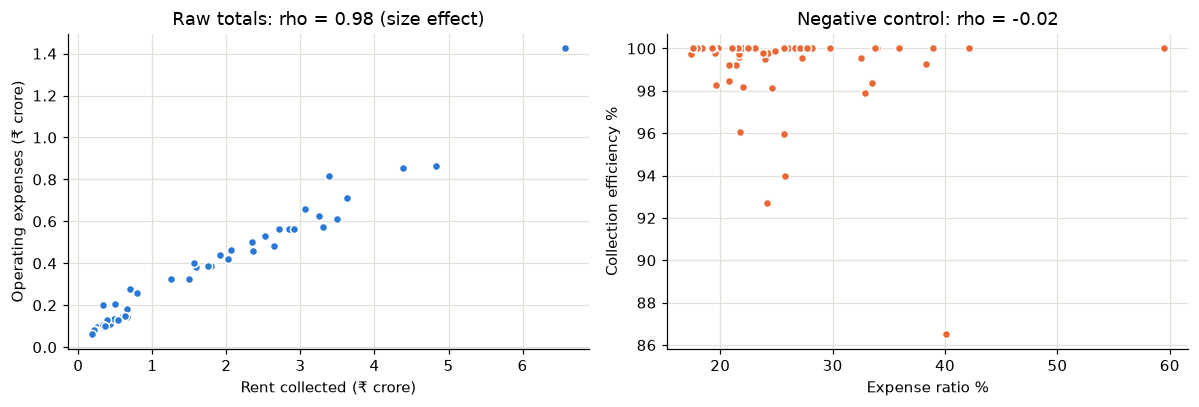

In [11]:
def spearman_ci(x, y, n_boot=2000):
    x, y = np.asarray(x), np.asarray(y)
    r = stats.spearmanr(x, y).statistic
    boots = []
    for _ in range(n_boot):
        i = RNG.integers(0, len(x), len(x))
        boots.append(stats.spearmanr(x[i], y[i]).statistic)
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return r, lo, hi

potential = leases.groupby('property_id').apply(lambda g: (g.monthly_rent_paise).max()).reindex(perf.index)
tests = {
    'raw totals: opex vs collected': (perf.opex, perf.collected),
    'per sq ft: opex vs collected': (perf.opex / perf.rentable_area_sqft, perf.collected / perf.rentable_area_sqft),
    'negative control: expense ratio vs collection efficiency': (perf['expense_ratio_%'], perf['collection_eff_%']),
}
corr = pd.DataFrame([(k, *spearman_ci(*v)) for k, v in tests.items()],
                    columns=['comparison', 'spearman_rho', 'ci95_low', 'ci95_high']).set_index('comparison')
corr['ci_excludes_0'] = (corr.ci95_low > 0) | (corr.ci95_high < 0)
display(corr)

monthly_tx = tx.groupby(['property_id', tx.transaction_date.dt.to_period('M')]).amount_received_paise.sum()
monthly_ex = ex.groupby(['property_id', ex.expense_date.dt.to_period('M')]).amount_paise.sum()
both = pd.concat([monthly_tx.rename('collected'), monthly_ex.rename('opex')], axis=1).fillna(0)
within = both.groupby(level=0).apply(lambda g: stats.spearmanr(g.collected, g.opex).statistic if g.collected.std() > 0 else np.nan)
print(f'Within-property monthly correlation (collected vs opex): median rho = {within.median():.2f}, '
      f'IQR {within.quantile(0.25):.2f} to {within.quantile(0.75):.2f} across {within.notna().sum()} properties')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(perf.collected / 1e9, perf.opex / 1e9, color=BLUE, s=28, edgecolor='white')
axes[0].set_xlabel('Rent collected (₹ crore)'); axes[0].set_ylabel('Operating expenses (₹ crore)')
axes[0].set_title(f"Raw totals: rho = {corr.iloc[0].spearman_rho:.2f} (size effect)")
axes[1].scatter(perf['expense_ratio_%'], perf['collection_eff_%'], color=ORANGE, s=28, edgecolor='white')
axes[1].set_xlabel('Expense ratio %'); axes[1].set_ylabel('Collection efficiency %')
axes[1].set_title(f"Negative control: rho = {corr.iloc[2].spearman_rho:.2f}")
save(fig, 'fig_correlation')

## 12. Temporal trends and seasonality

Monsoon / other months ratio = 2.01; one-sided Mann-Whitney p = 3.19e-06


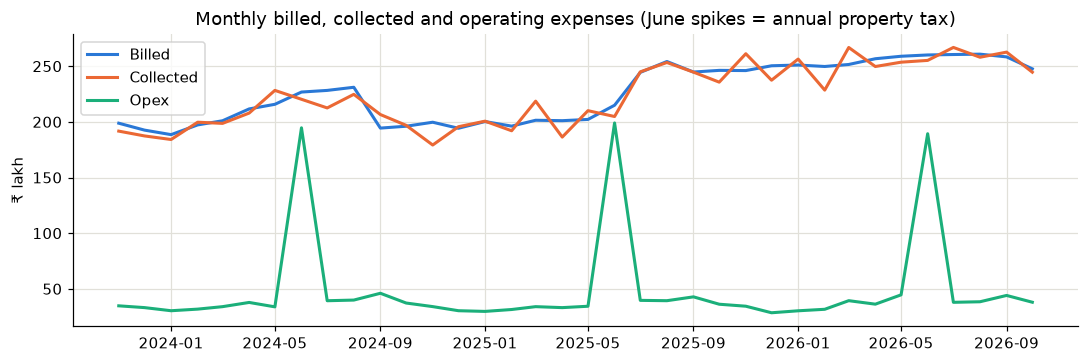

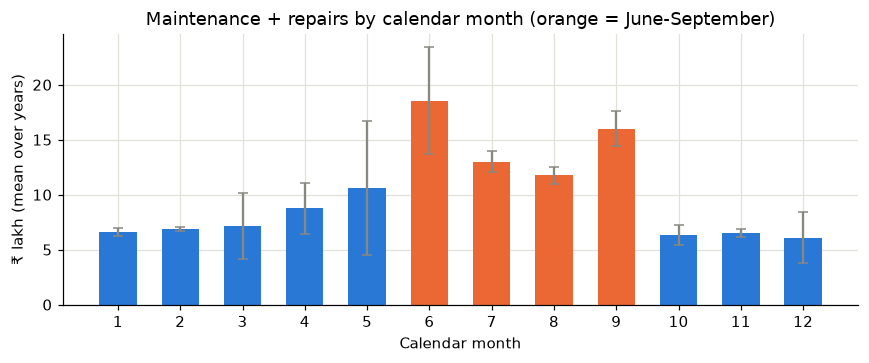

In [12]:
monthly = pd.DataFrame({
    'billed': ob.groupby(ob.due_date.dt.to_period('M')).due_amount_paise.sum(),
    'collected': tx.groupby(tx.transaction_date.dt.to_period('M')).amount_received_paise.sum(),
    'opex': ex.groupby(ex.expense_date.dt.to_period('M')).amount_paise.sum(),
}) / 1e7  # paise -> lakh rupees
fig, ax = plt.subplots(figsize=(10, 3.4))
for col, c in [('billed', BLUE), ('collected', ORANGE), ('opex', AQUA)]:
    ax.plot(monthly.index.to_timestamp(), monthly[col], color=c, linewidth=2, label=col.title())
ax.set_ylabel('₹ lakh'); ax.legend(); ax.set_title('Monthly billed, collected and operating expenses (June spikes = annual property tax)')
save(fig, 'fig_monthly_trend')

mr = ex[ex.expense_category.isin(['MAINTENANCE', 'REPAIRS'])]
mr_month = mr.groupby(mr.expense_date.dt.to_period('M')).amount_paise.sum() / 1e7
cal = mr_month.groupby(mr_month.index.month).agg(['mean', 'std', 'count'])
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(cal.index, cal['mean'], color=[ORANGE if m in (6, 7, 8, 9) else BLUE for m in cal.index], width=0.6)
ax.errorbar(cal.index, cal['mean'], yerr=cal['std'], fmt='none', ecolor=GREY, capsize=3)
ax.set_xticks(range(1, 13)); ax.set_xlabel('Calendar month'); ax.set_ylabel('₹ lakh (mean over years)')
ax.set_title('Maintenance + repairs by calendar month (orange = June-September)')
save(fig, 'fig_monsoon')
is_monsoon = np.isin(mr_month.index.month, [6, 7, 8, 9])
mw_season = stats.mannwhitneyu(mr_month[is_monsoon], mr_month[~is_monsoon], alternative='greater')
season_ratio = mr_month[is_monsoon].mean() / mr_month[~is_monsoon].mean()
print(f'Monsoon / other months ratio = {season_ratio:.2f}; one-sided Mann-Whitney p = {mw_season.pvalue:.2e}')

## 13. Unusually large expense records
A robust z-score on log amounts within each property × category (median and MAD), as a cross-check on the application's
Tukey-fence approach. Large values are **prompts for review**, not evidence of wrongdoing.

In [13]:
rep = ex[ex.expense_category == 'REPAIRS'].copy()
rep['log_amt'] = np.log(rep.amount)
g = rep.groupby('property_id').log_amt
rep['robust_z'] = (rep.log_amt - g.transform('median')) / (1.4826 * g.transform(lambda s: stats.median_abs_deviation(s)) + 1e-9)
median_repair = rep.amount.median()
flagged = rep[rep.robust_z > 3.5]
outsized = rep[rep.amount > 8 * median_repair]
print(f'Repairs: {len(rep):,} records; {len(outsized)} exceed 8x the portfolio median (planted outsized repairs); '
      f'{len(flagged)} have robust z > 3.5 within their property.')
print(f'Outsized records also flagged by the robust z-score: {outsized.expense_id.isin(flagged.expense_id).sum()} of {len(outsized)}')
display(outsized[['expense_id', 'property_id', 'expense_date', 'amount']].sort_values('amount', ascending=False))

Repairs: 515 records; 6 exceed 8x the portfolio median (planted outsized repairs); 7 have robust z > 3.5 within their property.
Outsized records also flagged by the robust z-score: 3 of 6


,expense_id,property_id,expense_date,amount
8185,E0008186,P011,2026-05-24,"998,064.00"
1443,E0001444,P048,2024-04-17,"614,039.00"
1785,E0001786,P008,2024-06-06,"471,815.00"
5290,E0005291,P005,2025-06-28,"389,894.00"
7914,E0007915,P035,2026-04-17,"288,845.00"
5364,E0005365,P035,2025-07-06,"178,749.00"


## 14. Segmentation by property type

In [14]:
seg = perf.groupby('property_type').agg(properties=('billed', 'size'), billed=('billed', 'sum'), paid=('paid', 'sum'),
                                        collected=('collected', 'sum'), opex=('opex', 'sum'),
                                        area=('rentable_area_sqft', 'sum'))
seg['collection_eff_%'] = 100 * seg.paid / seg.billed
seg['expense_ratio_%'] = 100 * seg.opex / seg.collected
seg['surplus_per_sqft_₹_36m'] = (seg.collected - seg.opex) / 100 / seg.area
seg = seg.join(delay_by_type[['mean', 'P90']].rename(columns={'mean': 'mean_days_late', 'P90': 'P90_days_late'}))
display(seg[['properties', 'collection_eff_%', 'expense_ratio_%', 'surplus_per_sqft_₹_36m', 'mean_days_late', 'P90_days_late']])

,properties,collection_eff_%,expense_ratio_%,surplus_per_sqft_₹_36m,mean_days_late,P90_days_late
property_type,,,,,,
INDUSTRIAL,5,100.00,19.35,539.61,3.94,5.00
OFFICE,14,98.54,22.81,"2,414.79",6.70,21.00
RESIDENTIAL,20,99.43,28.92,927.90,3.39,8.00
RETAIL,11,99.44,20.03,"3,577.72",8.68,26.00


## 15. Did the analysis recover the planted ground truth?
The generator planted five patterns and one negative control (see `data/GENERATOR_SPEC.md`). Each row below states the
test, the statistic, and whether the pattern was recovered **from the data alone**.

In [15]:
biggest_drop = perf.eff_change_pts.idxmin()
outsized_share = outsized.expense_id.isin(flagged.expense_id).mean()
verdict = lambda ok: 'yes' if ok else 'no'
recovery = pd.DataFrame([
    ('1 Retail pays later', 'Mann-Whitney retail > residential',
     f'p = {mw.pvalue:.1e}, effect = {rank_biserial:.2f}', verdict(mw.pvalue < 0.01)),
    ('2 Monsoon maintenance spike', 'Mann-Whitney Jun-Sep > other months',
     f'ratio = {season_ratio:.2f}, p = {mw_season.pvalue:.1e}', verdict(mw_season.pvalue < 0.01 and season_ratio > 1.3)),
    ('3 Vacancy shock (P005, P006)', 'longest fully vacant run >= 8 months',
     f'found: {", ".join(vacant.index)}', verdict({'P005', 'P006'} <= set(vacant.index))),
    ('4 Outsized repairs', 'robust z > 3.5 within property',
     f'{outsized.expense_id.isin(flagged.expense_id).sum()} of {len(outsized)} portfolio-level extremes flagged',
     'yes' if outsized_share >= 0.8 else 'partly' if outsized_share > 0 else 'no'),
    ('5 Degrading collections (P008)', 'largest fall in collection efficiency',
     f'{biggest_drop}: {perf.loc[biggest_drop, "eff_change_pts"]:.1f} pts', verdict(biggest_drop == 'P008')),
    ('6 Negative control: no cost-collection link', '95% CI of rho includes 0',
     f'rho = {corr.iloc[2].spearman_rho:.2f} [{corr.iloc[2].ci95_low:.2f}, {corr.iloc[2].ci95_high:.2f}]', verdict(not corr.iloc[2].ci_excludes_0)),
], columns=['planted pattern', 'test', 'result', 'recovered'])
display(recovery)
print('Pattern 4 is only partly recovered: the generator multiplies a repair by 8-15x of that draw, so a planted outlier at a '
      'property with small repairs can stay below the portfolio-level cut, while large industrial repairs exceed it without '
      'being unusual for their own property. The within-property test is the more appropriate one; neither is perfect.')

,planted pattern,test,result,recovered
0,1 Retail pays later,Mann-Whitney retail > residential,"p = 7.2e-22, effect = 0.19",yes
1,2 Monsoon maintenance spike,Mann-Whitney Jun-Sep > other months,"ratio = 2.01, p = 3.2e-06",yes
2,"3 Vacancy shock (P005, P006)",longest fully vacant run >= 8 months,"found: P005, P006",yes
3,4 Outsized repairs,robust z > 3.5 within property,3 of 6 portfolio-level extremes flagged,partly
4,5 Degrading collections (P008),largest fall in collection efficiency,P008: -11.9 pts,yes
5,6 Negative control: no cost-collection link,95% CI of rho includes 0,"rho = -0.02 [-0.30, 0.28]",yes


Pattern 4 is only partly recovered: the generator multiplies a repair by 8-15x of that draw, so a planted outlier at a property with small repairs can stay below the portfolio-level cut, while large industrial repairs exceed it without being unusual for their own property. The within-property test is the more appropriate one; neither is perfect.


## 16. Evidence-based insights (synthetic portfolio)
Generated from the computed values above, so the text cannot drift from the numbers.

In [16]:
insights = [
    f"Collections are healthy overall: {pct(cohort_paid, billed)}% of rent billed was collected by the analysis date, "
    f"but {len(open_ob)} obligations (₹{open_ob.balance_paise.sum()/1e7:,.1f} lakh) remain open.",
    f"Payment behaviour differs by segment: retail tenants' payments average {delay_by_type.loc['RETAIL','mean']:.1f} days late "
    f"(P90 {delay_by_type.loc['RETAIL','P90']:.0f}) against {delay_by_type.loc['RESIDENTIAL','mean']:.1f} (P90 "
    f"{delay_by_type.loc['RESIDENTIAL','P90']:.0f}) for residential. Collections follow-up effort would be best weighted towards retail.",
    f"Delay percentiles from completed payments understate lateness in the tail: Kaplan-Meier, which includes open obligations, gives "
    f"P90 = {comparison.loc['P90','Kaplan-Meier incl. open']} and P95 = {comparison.loc['P95','Kaplan-Meier incl. open']} days, against "
    f"{comparison.loc['P90','completed only (application)']} and {comparison.loc['P95','completed only (application)']} for completed payments only.",
    f"Maintenance and repair spending is seasonal: June-September months average {season_ratio:.2f}x other months, so budgets "
    "and contractor capacity should be planned for the monsoon.",
    f"{biggest_drop}'s collection efficiency fell by {-perf.loc[biggest_drop,'eff_change_pts']:.1f} points from May 2025: a candidate for an account review.",
    f"Offices {', '.join(vacant.index)} had fully vacant spells of 8 months or more; vacancy, not collections, drove their weaker income.",
    "Expenses rise with property size (raw rho {:.2f}), but cost intensity is unrelated to collection performance (rho {:.2f}, CI includes 0). "
    "Spending more on a property is not associated with collecting better, and no causal claim is made either way.".format(
        corr.iloc[0].spearman_rho, corr.iloc[2].spearman_rho),
]
for i, s in enumerate(insights, 1):
    print(f'{i}. {s}')

1. Collections are healthy overall: 99.16% of rent billed was collected by the analysis date, but 56 obligations (₹68.1 lakh) remain open.
2. Payment behaviour differs by segment: retail tenants' payments average 8.7 days late (P90 26) against 3.4 (P90 8) for residential. Collections follow-up effort would be best weighted towards retail.
3. Delay percentiles from completed payments understate lateness in the tail: Kaplan-Meier, which includes open obligations, gives P90 = 19 and P95 = 37 days, against 16 and 29 for completed payments only.
4. Maintenance and repair spending is seasonal: June-September months average 2.01x other months, so budgets and contractor capacity should be planned for the monsoon.
5. P008's collection efficiency fell by 11.9 points from May 2025: a candidate for an account review.
6. Offices P005, P006 had fully vacant spells of 8 months or more; vacancy, not collections, drove their weaker income.
7. Expenses rise with property size (raw rho 0.98), but cost in

## 17. Limitations and possible extensions
- **Synthetic data.** Every pattern here was generated from documented rules. The value of this notebook is in showing that
  the methods recover planted signals and do not invent unplanted ones, not in market conclusions.
- **Unplanted variation exists:** for example, P010's weak collections come from one defaulting tenant, not a planted rule.
  The analysis describes it without inventing a cause.
- **No causal inference.** The correlations in §11 are descriptive.
- **Possible extension (not built, per decision D-010):** a simple forecast of monthly collections (for example a seasonal
  naive or exponential-smoothing baseline with backtesting) would add value only if evaluated honestly against a naive
  benchmark. It is proposed, not claimed.